# Building Smarter Agents with Reflection and Planning
### Hands-on workshop | Microsoft Foundry Agents v2 API + Responses API

**Goal:** Observe the behavioral difference between a one-shot answer, an explicit **plan → act** workflow, and an **act → critique → revise** workflow. 

All model calls use persisted Microsoft Foundry **prompt agents** and the **Responses API**.

## 1. Concept: Why should agents revisit their first answer?

- **One-shot:** a single request generates a final answer; omissions can pass unnoticed.

- **Planning:** decompose the task into explicit, checkable steps before producing the recommendation.

- **Reflection:** generate a draft, critique it against a rubric, then revise the draft.

- **Orchestration:** Python controls the loop, data, stopping conditions, and which specialized agent runs next. A prompt saying “think carefully” is *not* the same as an observable agentic loop.

In Agents v2 API, successive `openai.responses.create(...)` calls are connected by a `previous_response_id` value. The reference preserves the earlier output context; you do not need v1 threads/runs. We also pass explicit text to cross-agent stages to ensure the critic's findings reach the reviser.

**Important:** We will demonstrate visible *decision artifacts* (plan, draft, critique, revision), **not** hidden model chain-of-thought.

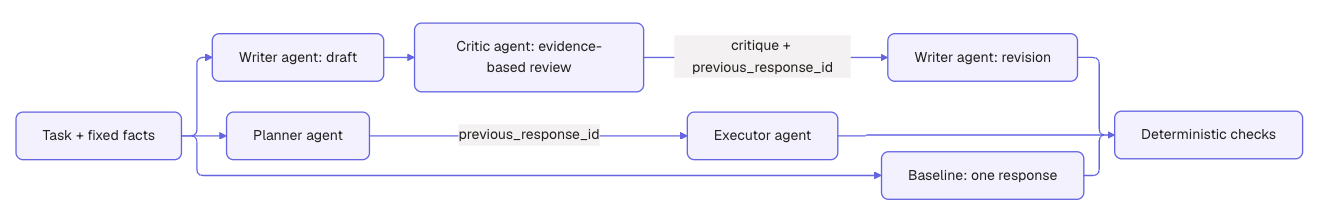

The key upgrade is not a bigger model. It is giving the workflow an opportunity to inspect its own intermediate work and correct it under explicit rules.

## 2. Prerequisites and Codespaces configuration

Either:

* Open this repository in **GitHub Codespaces**. The Codespace installs requirements and opens Jupyter automatically when the devcontainer starts. Open this notebook.

or:

* if you don't want to use GitHub Codespaces, open Visual Studio Code and open the folder containing this repository. Launch a Terminal and run this command: `python -m venv .venv && source .venv/bin/activate && pip install -r requirements.txt && jupyter lab`. Then, open this notebook.

1. Once the notebook is open, open a terminal and run `az login --use-device-code` to sign in with your Azure account.

2. In Microsoft Foundry, create a project and deploy a model suitable for prompt agents; copy the **project endpoint** (`https://<resource>.services.ai.azure.com/api/projects/<project>`), not the raw `/openai/v1/chat/completions` URL.

3. Run `cp .env.example .env` in the terminal. 

4. Open `.env`, set the values for both `FOUNDRY_PROJECT_ENDPOINT` and `FOUNDRY_MODEL_NAME` environment variables. Never commit `.env`.

5. Select the **Python 3** kernel for this notebook.

Execute the next cell to load the configuration for this tutorial

In [ ]:
import os, json, re, time
from pathlib import Path
from dotenv import load_dotenv
from IPython.display import display, Markdown
from azure.identity import DefaultAzureCredential
from azure.ai.projects import AIProjectClient
from azure.ai.projects.models import PromptAgentDefinition

load_dotenv(Path.cwd() / ".env")
load_dotenv(Path.cwd().parent / ".env", override=False)

ENDPOINT = os.getenv("FOUNDRY_PROJECT_ENDPOINT", "").strip()
MODEL = os.getenv("FOUNDRY_MODEL_NAME", "").strip()
PREFIX = os.getenv("AGENT_NAME_PREFIX", "reflection-lab").strip()

assert ENDPOINT.startswith("https://") and "/api/projects/" in ENDPOINT, "Set a valid FOUNDRY_PROJECT_ENDPOINT in .env"
assert MODEL, "Set FOUNDRY_MODEL_NAME in .env"

print("Configuration loaded. Model deployment:", MODEL)
print("Foundry endpoint:", ENDPOINT)

## 3. Our scenario:

A company must choose **one** analytics SaaS vendor. The **decision policy** goes as follows:

1. Budget cap: **$100,000 annual total cost**. Above cap means ineligible.

2. Security gate: **SOC 2 Type II required**. Missing means ineligible.

3. Residency gate: **EU data residency required**. Missing means ineligible.

4. Among eligible vendors choose the **lowest annual total cost**. If tied, choose higher support rating.

5. Mention at least one meaningful drawback of the selected option and explicitly name rejected vendors with reasons.

Run the following cell to load sample data as well as setting up initial variables according to the specifications defined in the above scenario.

In [ ]:
VENDORS = [
    {"name": "Northstar Analytics", "license_usd": 78000, "setup_usd": 12000, "soc2_type_ii": True, "eu_residency": True, "support_rating": 3, "drawback": "No 24/7 phone support"},
    {"name": "BluePeak Insights", "license_usd": 69000, "setup_usd": 8000, "soc2_type_ii": False, "eu_residency": True, "support_rating": 5, "drawback": "SOC 2 Type II report unavailable"},
    {"name": "Cedar Metrics", "license_usd": 82000, "setup_usd": 9000, "soc2_type_ii": True, "eu_residency": True, "support_rating": 5, "drawback": "More expensive than Northstar"},
    {"name": "Orbit Intelligence", "license_usd": 62000, "setup_usd": 10000, "soc2_type_ii": True, "eu_residency": False, "support_rating": 4, "drawback": "No EU residency"},
    {"name": "Summit BI", "license_usd": 91000, "setup_usd": 16000, "soc2_type_ii": True, "eu_residency": True, "support_rating": 5, "drawback": "Exceeds annual budget"},
]

BUDGET = 100000

TASK = ("Recommend one vendor based ONLY on the supplied data and policy. "
        "Explain the decision, show annual total costs, rejected alternatives, "
        "and the selected vendor's main drawback.")

DATA = json.dumps({"budget_usd": BUDGET, "vendors": VENDORS}, indent=2)
print(DATA)

## 4. Create four persistent Microsoft Foundry prompt agents

We create distinct roles because planning and critique are clearer when independently visible: 

* The **writer** handles both the first draft and revised output. 

* The **critic** returns inspectable findings; it does not independently approve a purchase.

> NOTE: Re-running this cell creates a new version of each named agent. The last section optionally deletes the versions created by this notebook.

In [ ]:
credential = DefaultAzureCredential(exclude_interactive_browser_credential=True)

project = AIProjectClient(endpoint=ENDPOINT, credential=credential)
openai = project.get_openai_client()

INSTRUCTIONS = {
    "writer": "You are a procurement analyst. Use only supplied facts. Clearly separate facts, calculations and recommendations. Do not invent facts. For revisions, address supplied critique and keep the final answer concise.",
    "planner": "You are a workflow planner. Break the task into concrete verification steps. Never make the vendor selection during planning. Use only the data provided.",
    "executor": "You are a meticulous procurement analyst. Execute each supplied plan step against supplied facts, showing calculations and constraints. Do not invent outside facts.",
    "critic": "You are an independent quality reviewer. Compare a draft to the stated policy and full dataset. Identify specific omissions, arithmetic mistakes, unsupported assertions, and policy violations. Do not invent problems; cite concrete vendor facts. End with 2-5 actionable revision requests. A good result can have zero issues.",
}

created_versions = []
AGENTS = {}

for role, instructions in INSTRUCTIONS.items():
    name = f"{PREFIX}-{role}"

    agent = project.agents.create_version(
        agent_name=name,
        definition=PromptAgentDefinition(model=MODEL, instructions=instructions),
    )

    created_versions.append((agent.name, agent.version))

    AGENTS[role] = agent.name

    print(f"Created {role}: {agent.name} (version {agent.version})")

## 5. Responses API helper + basic usage tracking

Every call below uses **Foundry's agent_reference** through a Responses API request. 

Record response IDs, duration and token counts for observability.

In [ ]:
RUN_LOG = []

def respond(role, input_text, previous_response_id=None):
    kwargs = {
        "input": input_text,
        "extra_body": {"agent_reference": {"name": AGENTS[role], "type": "agent_reference"}},
    }

    if previous_response_id:
        kwargs["previous_response_id"] = previous_response_id

    start = time.perf_counter()
    result = openai.responses.create(**kwargs)

    duration = time.perf_counter() - start
    usage = getattr(result, "usage", None)

    record = {
        "role": role, "response_id": result.id, "previous_response_id": previous_response_id,
        "seconds": round(duration, 2),
        "input_tokens": getattr(usage, "input_tokens", None),
        "output_tokens": getattr(usage, "output_tokens", None),
        "total_tokens": getattr(usage, "total_tokens", None),
    }

    RUN_LOG.append(record)

    return result

def show_result(title, response):
    display(Markdown(f"### {title}\n\n{response.output_text or '*No text returned*'}"))
    print("Response ID:", response.id)

## DEMO A — One-shot baseline

We start with a normal agent call: one task, one response, no explicit checkpoints. 

It might already succeed—but we cannot inspect intermediate verification steps.

In [ ]:
baseline = respond("writer", f"{TASK}\n\nPOLICY AND VENDOR DATA:\n{DATA}")
show_result("Baseline recommendation", baseline)

## DEMO B — Plan → Act

Before answering, the first agent writes a verifiable plan. The second agent executes that plan. We link the calls with `previous_response_id`.

The planner and executor are different agents. Because a cross-agent response chain may not always expose the earlier user's dataset to the second agent as expected, the execution input includes the **validated data and plan explicitly**, while retaining the response link for continuity.

Planning gives **structure**, not correctness guarantees. Our deterministic checks later test the result.

In [ ]:
plan_prompt = f"""Create a numbered 4-6 step verification plan for the following task.
Include arithmetic verification, each mandatory gate, ranking, and drawbacks.
Output a readable numbered list, not a final recommendation.

TASK: {TASK}
DATA: {DATA}"""

plan_result = respond("planner", plan_prompt)

show_result("Planner output", plan_result)

In [ ]:
execution_prompt = f"""Execute the following plan step by step and then give a final selection.
Use ONLY the original facts; check every gate and all total costs.

PLAN:
{plan_result.output_text}

ORIGINAL TASK:
{TASK}

ORIGINAL DATA:
{DATA}"""

execution_result = respond("executor", execution_prompt, previous_response_id=plan_result.id)

show_result("Plan-then-act recommendation", execution_result)

print("Chained to planner response:", plan_result.id)

## DEMO C — Act → Reflect → Revise

A draft is not the final answer. We introduce an independent reviewer, then have the author revise against concrete gaps.

Here the critic sees the policy, full dataset and draft. The writer's revision **chains from its own draft** using `previous_response_id`. The critique text is explicitly injected into the revision request because the critic is a separate agent.

This version runs **one reflection cycle**. Production systems can repeat with bounded cycles and independent quality gates.

In [ ]:
draft = respond("writer", f"Prepare a concise first-pass recommendation. {TASK}\n\nFACTS:\n{DATA}")
show_result("First draft", draft)

critique_prompt = f"""Review this draft against every mandatory rule and all supplied facts.
Do not assume the draft is wrong; report evidence-based gaps and specific repairs.

POLICY: {TASK}
FULL DATA: {DATA}
DRAFT: {draft.output_text}
"""

critique = respond("critic", critique_prompt)
show_result("Independent critique", critique)

In [ ]:
revision_prompt = f"""Revise your original draft to address the independent critique.
Explicitly fix any supported errors, and do not invent data.
If the critique raises a false issue, explain briefly why it is not a defect.

INDEPENDENT CRITIQUE:
{critique.output_text}

ORIGINAL TASK:
{TASK}
FULL DATA:
{DATA}"""

revised = respond("writer", revision_prompt, previous_response_id=draft.id)

show_result("Refined recommendation", revised)
print("Revision chained to original draft:", draft.id)

## 6. Deterministic ground truth and comparison

The critic and writer are probabilistic. **Quality must be checked independently.** 

The following basic evaluator uses objective source data to identify the correct eligible vendor. An optional text-based checklist is a *demo heuristic*, not semantic correctness evaluation.

In [ ]:
def eligible(v):
    return (v["license_usd"] + v["setup_usd"] <= BUDGET
            and v["soc2_type_ii"] and v["eu_residency"])

ranked = sorted((v for v in VENDORS if eligible(v)),
                key=lambda v: (v["license_usd"] + v["setup_usd"], -v["support_rating"]))

winner = ranked[0]

print("Ground-truth qualified vendors:", [(v["name"], v["license_usd"]+v["setup_usd"]) for v in ranked])
print("Expected recommendation:", winner["name"])
assert winner["name"] == "Northstar Analytics"

# These are surface-level indicators, NOT proof the answer is correct.
def checklist(text):
    t = text.lower()
    return {
        "mentions_expected_winner": winner["name"].lower() in t,
        "mentions_all_vendors": all(v["name"].lower() in t for v in VENDORS),
        "mentions_security_gate": "soc 2" in t or "soc2" in t,
        "mentions_residency": "residen" in t,
        "mentions_a_drawback": "support" in t or "drawback" in t or "limitation" in t,
    }

outputs = {"One-shot": baseline.output_text or "", "Plan → Act": execution_result.output_text or "", "Reflect → Revise": revised.output_text or ""}

for name, text in outputs.items():
    flags = checklist(text)

    print(f"\n{name}: {sum(flags.values())}/{len(flags)} surface-level checks")

    for k, ok in flags.items():
        print("  ", "PASS" if ok else "CHECK", k)

## 7. Token usage, latency and the cost of iteration

Each additional model call creates overhead. These numbers are **observed usage**, not a normalized price comparison: different roles and inputs use different token counts.

In [ ]:
from collections import defaultdict
for r in RUN_LOG:
    print(f"{r['role']:9} {r['seconds']:6.2f}s  "
          f"input={r['input_tokens']} output={r['output_tokens']} total={r['total_tokens']}")
print("\nTotal model calls:", len(RUN_LOG))
print("Total reported tokens:", sum(r['total_tokens'] or 0 for r in RUN_LOG))

## 8. Additional challenges

You can try the following exercises to understand the impact of Reflection and Planning:

1. Deliberately remove a mandatory rule from the writer instructions or use a shorter first-pass prompt. Does the critic catch the omission?

2. Run a second **critique → revise** cycle only if independent checks fail. Never allow unbounded iteration.

3. Require the planner to output JSON and validate the schema before executing. The response format supported by your model can be requested via `text.format` / `extra_body`.

4. Replace the procurement task with **code review**, where the critic checks input validation, error handling, secrets and performance. Use external tests or a linter to judge the result.

**Discussion:** When would you use no reflection? When is an independent critic insufficient? What happens if both models confidently agree on a wrong assumption?

## Conclusion

* Planning organizes work

* Reflection creates an explicit opportunity for correction

* External validation determines whether the output is acceptable.

* **Agents become more dependable when we design the process around them: plan, execute, question the output, validate, and revise only when needed.**

## 9. Optional cleanup — remove only the agent versions from this notebook

Skip cleanup if you want to inspect your agents in Microsoft Foundry. Response history and project-level telemetry may have their own retention/cleanup policies.

In [ ]:
# Uncomment and run ONLY if you want to delete the versions created above.
# for agent_name, agent_version in reversed(created_versions):
#     project.agents.delete_version(agent_name=agent_name, agent_version=agent_version)
#     print("Deleted", agent_name, agent_version)
# openai.close()
# project.close()
# credential.close()

## Resources

- [Implement agent reflection and planning cycles — Microsoft Learn](https://learn.microsoft.com/en-us/training/modules/aaai-design-agentic-loops-azure-ai-agent-service/4-implement-agent-reflection-planning-cycles)

- [Foundry prompt agent quickstart](https://learn.microsoft.com/en-us/azure/foundry/agents/quickstarts/prompt-agent)

- [Azure AI Projects Python SDK](https://learn.microsoft.com/en-us/python/api/overview/azure/ai-projects-readme)